
# Detecção de Anomalias em Transações de Cartão de Crédito

## 1. Introdução

Este projeto tem como objetivo desenvolver modelos de Machine Learning capazes de identificar transações fraudulentas em cartões de crédito.

Será utilizada uma base de dados real, disponibilizada pelo TensorFlow, contendo informações de transações financeiras.

O principal desafio é o desbalanceamento dos dados: a quantidade de transações legítimas é muito superior à quantidade de fraudes.

Por isso, serão utilizadas métricas como Precision, Recall e F1-Score para avaliar os modelos.


In [ ]:

# 1. Importação das bibliotecas

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração dos gráficos
sns.set_theme(style="whitegrid")

# Endereço da base de dados
url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"

# Carregamento dos dados
df = pd.read_csv(url)

# Exibição das primeiras linhas
display(df.head())



## 2. Análise Exploratória dos Dados

Nesta etapa, será analisada a distribuição das classes existentes na base de dados.

O objetivo é identificar a proporção entre transações legítimas e fraudulentas, verificando o nível de desbalanceamento do conjunto de dados.

Essa análise é fundamental para definir as métricas adequadas de avaliação dos modelos.


In [ ]:

# Quantidade de transações por classe
distribuicao = df['Class'].value_counts()

# Proporção de cada classe
proporcao = df['Class'].value_counts(normalize=True) * 100

print("QUANTIDADE DE TRANSAÇÕES")
print(distribuicao)

print("\nPROPORÇÃO DAS CLASSES (%)")
print(proporcao.round(4))

print("\nTOTAL DE TRANSAÇÕES:")
print(len(df))


In [ ]:

# Gráfico da distribuição das classes

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Class')

plt.title('Distribuição de Transações: Legítimas x Fraudulentas')
plt.xlabel('Classe (0 = Legítima | 1 = Fraude)')
plt.ylabel('Quantidade de Transações')

plt.xticks([0, 1], ['Legítimas', 'Fraudulentas'])

plt.show()



## 3. Preparação dos Dados

Nesta etapa, serão realizadas transformações nas variáveis e a divisão dos dados em conjuntos de treinamento e teste.

A variável Amount receberá uma transformação logarítmica utilizando np.log1p, reduzindo a influência de valores extremos.

A divisão será estratificada para preservar a proporção entre transações legítimas e fraudulentas nos dois conjuntos.

A padronização será realizada posteriormente dentro de um Pipeline, evitando vazamento de informações entre treino e teste.


In [ ]:

# Verificação da estrutura dos dados

print("DIMENSÕES DA BASE:")
print(df.shape)

print("\nVALORES AUSENTES:")
print(df.isnull().sum().sum())

print("\nTIPOS DAS VARIÁVEIS:")
print(df.dtypes.value_counts())

print("\nESTATÍSTICAS DA COLUNA AMOUNT:")
display(df['Amount'].describe())


In [ ]:

from sklearn.model_selection import train_test_split

# Criando uma cópia da base
df_model = df.copy()

# Transformação logarítmica do valor das transações
df_model['Amount'] = np.log1p(df_model['Amount'])

# Separação das variáveis preditoras e da variável alvo
X = df_model.drop(columns=['Class'])
y = df_model['Class']

# Divisão estratificada: 80% treinamento e 20% teste
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Conferindo os resultados
print("TREINAMENTO:")
print(X_train.shape)
print(y_train.value_counts())

print("\nTESTE:")
print(X_test.shape)
print(y_test.value_counts())



### 3.1. Resultados da preparação

A base possui 284.807 transações e não apresenta valores ausentes.

Foram identificadas 492 transações fraudulentas, correspondentes a aproximadamente 0,1727% do total.

Após a divisão estratificada, obtivemos 227.845 registros para treinamento e 56.962 para teste, preservando a proporção entre as classes.

A variável Amount foi transformada utilizando np.log1p, e a padronização será realizada dentro dos Pipelines dos modelos.



## 4. Treinamento dos Modelos

### 4.1. Regressão Logística

A Regressão Logística será utilizada como primeiro modelo de classificação e servirá como referência para os demais algoritmos.

Será utilizado o StandardScaler para padronizar as variáveis e class_weight='balanced' para atribuir maior peso à classe minoritária.

O desempenho será avaliado por meio de Precision, Recall, F1-Score, matriz de confusão e métricas de área sob as curvas ROC e Precision-Recall.


In [ ]:

# Importação das ferramentas necessárias

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Criação do Pipeline
modelo_logistico = Pipeline([
    ('scaler', StandardScaler()),
    ('modelo', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

# Treinamento
modelo_logistico.fit(X_train, y_train)

print("Modelo de Regressão Logística treinado com sucesso!")


In [ ]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Previsões no conjunto de teste
y_pred_log = modelo_logistico.predict(X_test)

# Probabilidades de fraude
y_prob_log = modelo_logistico.predict_proba(X_test)[:, 1]

# Relatório de classificação
print("RELATÓRIO DE CLASSIFICAÇÃO")
print(classification_report(
    y_test,
    y_pred_log,
    target_names=['Legítima', 'Fraude'],
    digits=4
))

# Métricas adicionais
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_log), 4))

print("PR-AUC (Average Precision):",
      round(average_precision_score(y_test, y_prob_log), 4))

# Matriz de confusão
print("\nMATRIZ DE CONFUSÃO")
print(confusion_matrix(y_test, y_pred_log))



### 4.2. Análise da Regressão Logística

O primeiro modelo apresentou Recall de 91,84% para a classe fraudulenta, identificando 90 das 98 fraudes existentes no conjunto de teste.

Entretanto, sua Precision foi de apenas 6,03%, indicando uma quantidade elevada de falsos positivos.

Foram registrados 1.403 falsos positivos e 8 falsos negativos.

O modelo apresentou ROC-AUC de 0,9711 e PR-AUC de 0,7113.

Os resultados demonstram que a Regressão Logística consegue identificar grande parte das fraudes, mas ainda precisa melhorar o equilíbrio entre a identificação de transações fraudulentas e a redução de alarmes incorretos.



## 5. Modelo Random Forest

O Random Forest será utilizado para verificar se um conjunto de árvores de decisão consegue melhorar a identificação de transações fraudulentas.

Será utilizado class_weight='balanced' para compensar o desbalanceamento entre as classes.

O desempenho será comparado com o modelo de Regressão Logística, utilizando exatamente os mesmos dados de treinamento e teste.


In [ ]:

from sklearn.ensemble import RandomForestClassifier

# Criação do modelo
modelo_rf = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# Treinamento
modelo_rf.fit(X_train, y_train)

print("Random Forest treinado com sucesso!")


In [ ]:

# Previsões
y_pred_rf = modelo_rf.predict(X_test)

# Probabilidades de fraude
y_prob_rf = modelo_rf.predict_proba(X_test)[:, 1]

# Relatório de classificação
print("RELATÓRIO RANDOM FOREST")

print(classification_report(
    y_test,
    y_pred_rf,
    target_names=['Legítima', 'Fraude'],
    digits=4
))

# Métricas adicionais
print("ROC-AUC:",
      round(roc_auc_score(y_test, y_prob_rf), 4))

print("PR-AUC:",
      round(average_precision_score(y_test, y_prob_rf), 4))

# Matriz de confusão
print("\nMATRIZ DE CONFUSÃO")
print(confusion_matrix(y_test, y_pred_rf))


In [ ]:

# Comparação inicial dos modelos

resultados = pd.DataFrame({
    'Modelo': ['Regressão Logística', 'Random Forest'],
    'Precision': [
        0.0603,
        classification_report(
            y_test, y_pred_rf,
            output_dict=True
        )['1']['precision']
    ],
    'Recall': [
        0.9184,
        classification_report(
            y_test, y_pred_rf,
            output_dict=True
        )['1']['recall']
    ],
    'F1-Score': [
        0.1131,
        classification_report(
            y_test, y_pred_rf,
            output_dict=True
        )['1']['f1-score']
    ],
    'PR-AUC': [
        average_precision_score(y_test, y_prob_log),
        average_precision_score(y_test, y_prob_rf)
    ]
})

display(resultados.round(4))



## 6. Modelo XGBoost

O XGBoost será utilizado como terceiro algoritmo de classificação.

Será aplicado o parâmetro scale_pos_weight para compensar o desbalanceamento das classes, atribuindo maior peso às transações fraudulentas.

O desempenho será avaliado pelas mesmas métricas utilizadas nos modelos anteriores.


In [ ]:

%pip install -q xgboost

from xgboost import XGBClassifier

print("XGBoost instalado e importado com sucesso!")


In [ ]:

# Calculando o peso da classe minoritária
peso_fraude = (
    (y_train == 0).sum() /
    (y_train == 1).sum()
)

print("Peso aplicado às fraudes:", peso_fraude)

# Criando o modelo
modelo_xgb = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=peso_fraude,
    eval_metric='aucpr',
    random_state=42,
    n_jobs=-1
)

# Treinamento
modelo_xgb.fit(X_train, y_train)

print("XGBoost treinado com sucesso!")


In [ ]:

# Previsões
y_pred_xgb = modelo_xgb.predict(X_test)

# Probabilidades de fraude
y_prob_xgb = modelo_xgb.predict_proba(X_test)[:, 1]

# Relatório
print("RELATÓRIO XGBOOST")

print(classification_report(
    y_test,
    y_pred_xgb,
    target_names=['Legítima', 'Fraude'],
    digits=4
))

# Métricas adicionais
print("ROC-AUC:",
      round(roc_auc_score(y_test, y_prob_xgb), 4))

print("PR-AUC:",
      round(average_precision_score(y_test, y_prob_xgb), 4))

# Matriz de confusão
print("\nMATRIZ DE CONFUSÃO")
print(confusion_matrix(y_test, y_pred_xgb))


In [ ]:

# Comparação dos três modelos

modelos = {
    'Regressão Logística': (y_prob_log, y_pred_log),
    'Random Forest': (y_prob_rf, y_pred_rf),
    'XGBoost': (y_prob_xgb, y_pred_xgb)
}

resultados_finais = []

for nome, (probabilidades, previsoes) in modelos.items():

    relatorio = classification_report(
        y_test,
        previsoes,
        output_dict=True,
        zero_division=0
    )

    resultados_finais.append({
        'Modelo': nome,
        'Precision': relatorio['1']['precision'],
        'Recall': relatorio['1']['recall'],
        'F1-Score': relatorio['1']['f1-score'],
        'ROC-AUC': roc_auc_score(y_test, probabilidades),
        'PR-AUC': average_precision_score(y_test, probabilidades)
    })

comparacao = pd.DataFrame(resultados_finais)

display(comparacao.round(4))


## 7. Ajuste do limiar de decisão

Nesta etapa, será testado um limiar de decisão de 0,3, em substituição ao padrão de 0,5.

O objetivo é verificar se a alteração aumenta a detecção de transações fraudulentas e avaliar o impacto sobre os falsos positivos.

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

def avaliar_limiar(nome, probabilidades, limiar):
    previsoes = (probabilidades >= limiar).astype(int)

    print(f"\n{nome} — Limiar: {limiar}")
    print("Precision:", round(precision_score(y_test, previsoes), 4))
    print("Recall:", round(recall_score(y_test, previsoes), 4))
    print("F1-Score:", round(f1_score(y_test, previsoes), 4))
    print("Matriz de confusão:")
    print(confusion_matrix(y_test, previsoes))


avaliar_limiar("Random Forest", y_prob_rf, 0.3)
avaliar_limiar("XGBoost", y_prob_xgb, 0.3)

## 7. Otimização de Hiperparâmetros com GridSearchCV

Será utilizado o GridSearchCV para encontrar uma configuração otimizada do modelo Random Forest.

A métrica de seleção será o Recall, buscando aumentar a capacidade de identificação de transações fraudulentas.

A validação cruzada será estratificada para preservar a proporção entre as classes.

In [23]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier

# Amostra estratificada de 50% dos dados de treinamento
X_amostra = X_train.sample(
    frac=0.5,
    random_state=42
)

y_amostra = y_train.loc[X_amostra.index]

# Parâmetros reduzidos para otimizar o tempo
parametros = {
    'n_estimators': [100, 150],
    'max_depth': [10, 20],
    'class_weight': ['balanced']
}

validacao = StratifiedKFold(
    n_splits=2,
    shuffle=True,
    random_state=42
)

busca_rf = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),
    param_grid=parametros,
    scoring='recall',
    cv=validacao,
    n_jobs=1,
    verbose=1
)

busca_rf.fit(X_amostra, y_amostra)

print("Melhores parâmetros:", busca_rf.best_params_)
print("Melhor Recall:", round(busca_rf.best_score_, 4))

Fitting 2 folds for each of 4 candidates, totalling 8 fits
Melhores parâmetros: {'class_weight': 'balanced', 'max_depth': 10, 'n_estimators': 100}
Melhor Recall: 0.6737


In [21]:
print("X_train existe:", 'X_train' in globals())
print("y_train existe:", 'y_train' in globals())
print("X_test existe:", 'X_test' in globals())
print("y_test existe:", 'y_test' in globals())
print("modelo_rf existe:", 'modelo_rf' in globals())

X_train existe: True
y_train existe: True
X_test existe: True
y_test existe: True
modelo_rf existe: True


In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Criar o modelo com os melhores parâmetros encontrados
modelo_rf_otimizado = RandomForestClassifier(
    **busca_rf.best_params_,
    random_state=42,
    n_jobs=-1
)

# Treinar com todos os dados de treinamento
modelo_rf_otimizado.fit(X_train, y_train)

# Fazer previsões no conjunto de teste
y_pred_rf_otimizado = modelo_rf_otimizado.predict(X_test)
y_prob_rf_otimizado = modelo_rf_otimizado.predict_proba(X_test)[:, 1]

# Avaliar resultados
print("RELATÓRIO RANDOM FOREST OTIMIZADO")
print(classification_report(
    y_test,
    y_pred_rf_otimizado,
    target_names=['Legítima', 'Fraude'],
    digits=4
))

print("ROC-AUC:", round(
    roc_auc_score(y_test, y_prob_rf_otimizado), 4
))

print("PR-AUC:", round(
    average_precision_score(y_test, y_prob_rf_otimizado), 4
))

print("\nMATRIZ DE CONFUSÃO")
print(confusion_matrix(y_test, y_pred_rf_otimizado))

RELATÓRIO RANDOM FOREST OTIMIZADO
              precision    recall  f1-score   support

    Legítima     0.9997    0.9997    0.9997     56864
      Fraude     0.8182    0.8265    0.8223        98

    accuracy                         0.9994     56962
   macro avg     0.9089    0.9131    0.9110     56962
weighted avg     0.9994    0.9994    0.9994     56962

ROC-AUC: 0.9766
PR-AUC: 0.8177

MATRIZ DE CONFUSÃO
[[56846    18]
 [   17    81]]


In [25]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Aplicar limiar de 0.3 às probabilidades do modelo otimizado
y_pred_rf_otimizado_03 = (
    y_prob_rf_otimizado >= 0.3
).astype(int)

print("RANDOM FOREST OTIMIZADO — LIMIAR 0.3")

print("Precision:", round(
    precision_score(y_test, y_pred_rf_otimizado_03), 4
))

print("Recall:", round(
    recall_score(y_test, y_pred_rf_otimizado_03), 4
))

print("F1-Score:", round(
    f1_score(y_test, y_pred_rf_otimizado_03), 4
))

print("\nMATRIZ DE CONFUSÃO")
print(confusion_matrix(y_test, y_pred_rf_otimizado_03))

RANDOM FOREST OTIMIZADO — LIMIAR 0.3
Precision: 0.5931
Recall: 0.8776
F1-Score: 0.7078

MATRIZ DE CONFUSÃO
[[56805    59]
 [   12    86]]


## 8. Importância das Variáveis

Nesta etapa, será analisada a importância das variáveis utilizadas pelo modelo Random Forest.

O objetivo é identificar quais características possuem maior contribuição para as decisões de classificação de transações legítimas e fraudulentas.

,Variável,Importância
14,V14,0.172755
4,V4,0.115382
10,V10,0.111231
12,V12,0.093417
17,V17,0.092719
3,V3,0.064234
11,V11,0.058795
16,V16,0.051311
2,V2,0.028824
7,V7,0.025840


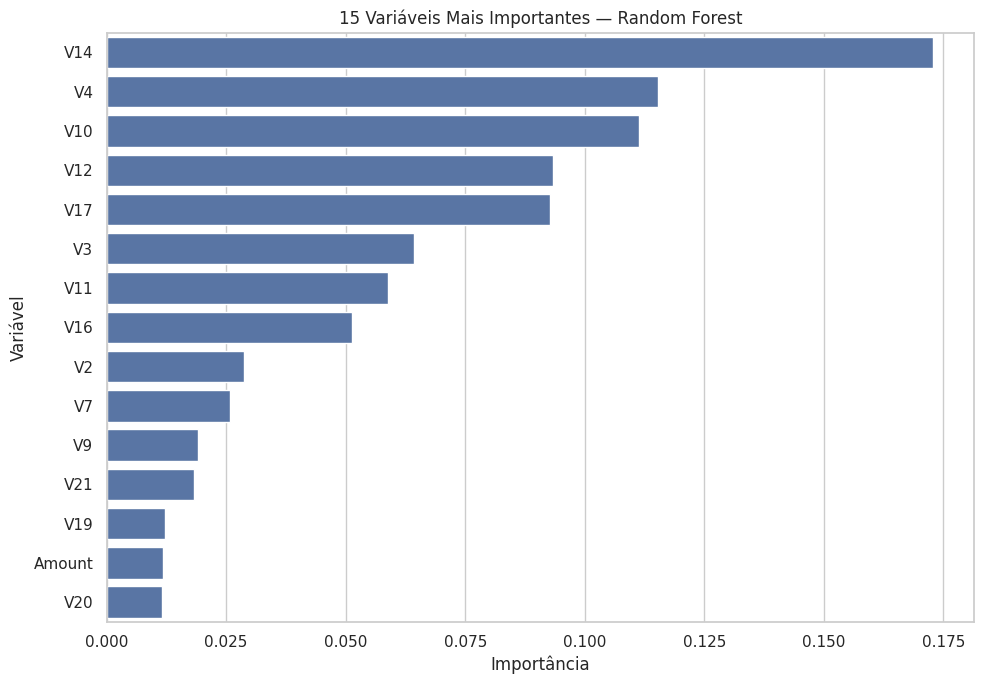

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extrair a importância das variáveis
importancias = pd.DataFrame({
    'Variável': X_train.columns,
    'Importância': modelo_rf.feature_importances_
})

# Ordenar da maior para a menor importância
importancias = importancias.sort_values(
    by='Importância',
    ascending=False
)

# Exibir as 15 variáveis mais importantes
display(importancias.head(15))

# Criar gráfico
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importancias.head(15),
    x='Importância',
    y='Variável'
)

plt.title('15 Variáveis Mais Importantes — Random Forest')
plt.xlabel('Importância')
plt.ylabel('Variável')
plt.tight_layout()
plt.show()

## 9. Explicabilidade do Modelo com SHAP

Será utilizada a biblioteca SHAP (SHapley Additive exPlanations) para interpretar as previsões do Random Forest.

A análise permitirá identificar a contribuição das variáveis para as classificações realizadas pelo modelo, tanto de forma geral quanto individual.

In [27]:
%pip install -q shap

In [28]:
import shap

print("SHAP instalado e importado com sucesso!")

SHAP instalado e importado com sucesso!


In [29]:
# Selecionar uma amostra do conjunto de teste
X_shap = X_test.sample(
    n=1000,
    random_state=42
)

# Criar o explicador para o Random Forest original
explainer = shap.TreeExplainer(modelo_rf)

# Calcular os valores SHAP
shap_values = explainer.shap_values(X_shap)

# Selecionar os valores referentes à classe Fraude (1)
if isinstance(shap_values, list):
    valores_fraude = shap_values[1]
elif len(shap_values.shape) == 3:
    valores_fraude = shap_values[:, :, 1]
else:
    valores_fraude = shap_values

print("Análise SHAP calculada com sucesso!")
print("Formato dos valores:", valores_fraude.shape)

Análise SHAP calculada com sucesso!
Formato dos valores: (1000, 30)


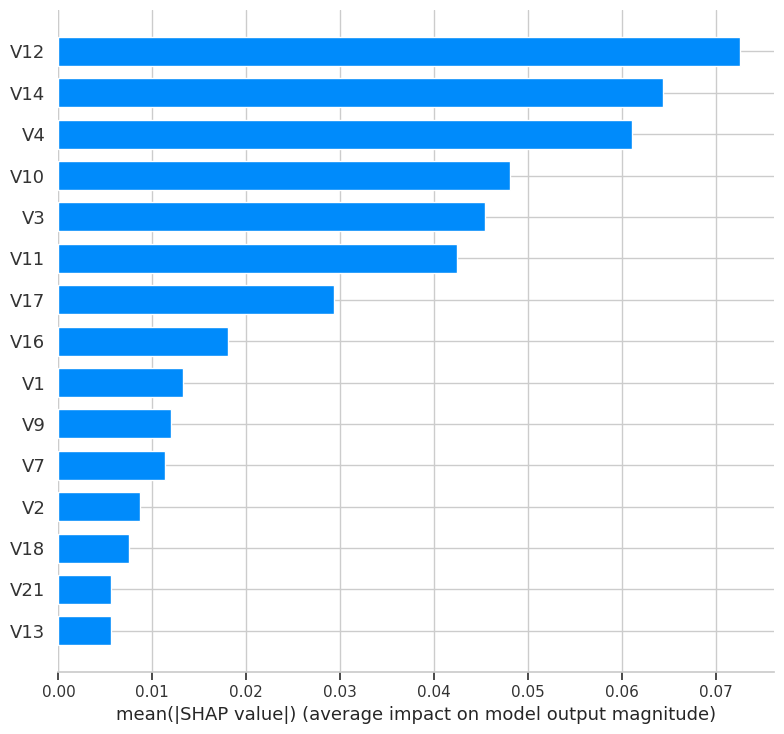

In [30]:
shap.summary_plot(
    valores_fraude,
    X_shap,
    plot_type='bar',
    max_display=15
)

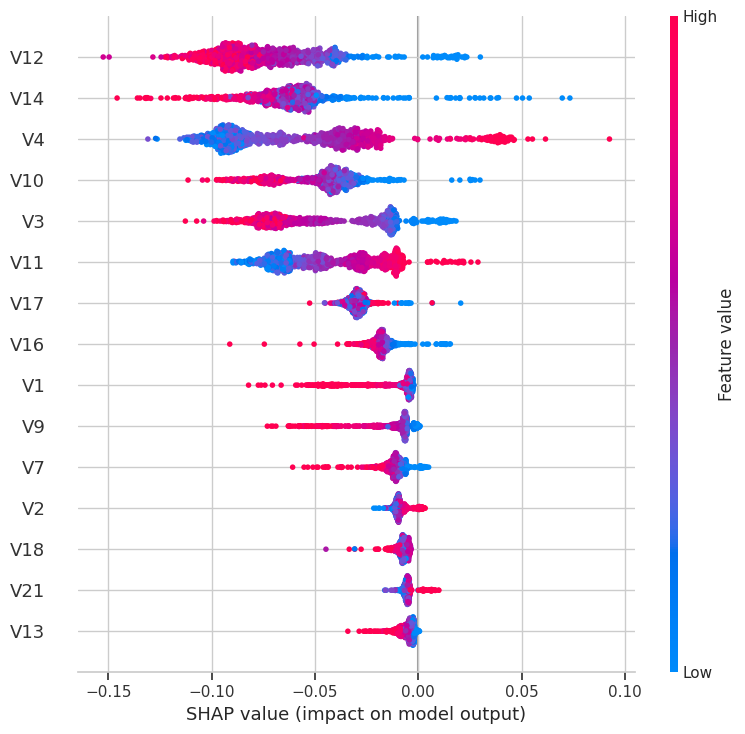

In [31]:
shap.summary_plot(
    valores_fraude,
    X_shap,
    max_display=15
)

### 9.5. Interpretação dos Resultados SHAP

A análise SHAP permitiu investigar a influência das variáveis nas previsões realizadas pelo modelo Random Forest.

Os resultados indicaram que as variáveis V12, V14 e V4 apresentaram os maiores impactos médios sobre as previsões, seguidas por V10, V3 e V11.

Observou-se também uma correspondência entre os resultados SHAP e a importância tradicional das variáveis calculada pelo Random Forest, especialmente em relação a V14, V4, V10, V12 e V3.

Essa análise demonstra que diferentes métodos de interpretação podem oferecer perspectivas complementares sobre o comportamento de um modelo de aprendizado de máquina.

É importante ressaltar que as variáveis V1 a V28 foram transformadas por Análise de Componentes Principais (PCA) no conjunto de dados original. Portanto, seus significados individuais não podem ser interpretados diretamente como características específicas de uma transação.

O SHAP fornece explicações sobre as contribuições das variáveis para as previsões do modelo, não estabelecendo relações de causalidade nem comprovando a ocorrência de fraude.

## 10. Avaliação Gráfica dos Modelos

Nesta etapa, serão construídas as curvas ROC e Precision-Recall para comparar o desempenho dos modelos de Regressão Logística, Random Forest e XGBoost.

As visualizações permitirão analisar a capacidade de discriminação dos algoritmos e seu desempenho na identificação de transações fraudulentas.

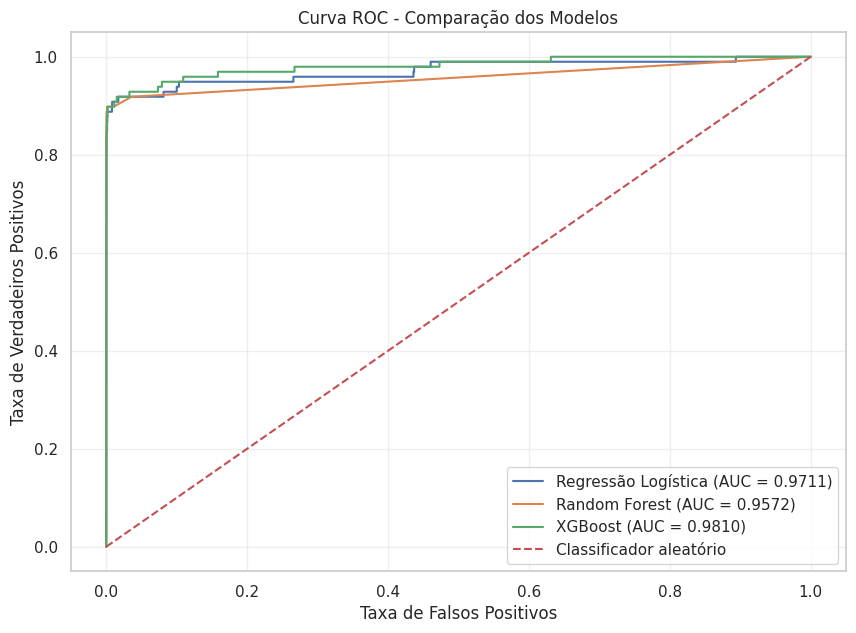

In [32]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Probabilidades dos três modelos
modelos_probabilidades = {
    'Regressão Logística': y_prob_log,
    'Random Forest': y_prob_rf,
    'XGBoost': y_prob_xgb
}

plt.figure(figsize=(10, 7))

for nome, probabilidades in modelos_probabilidades.items():
    fpr, tpr, _ = roc_curve(y_test, probabilidades)
    valor_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f'{nome} (AUC = {valor_auc:.4f})'
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Classificador aleatório'
)

plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC - Comparação dos Modelos')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

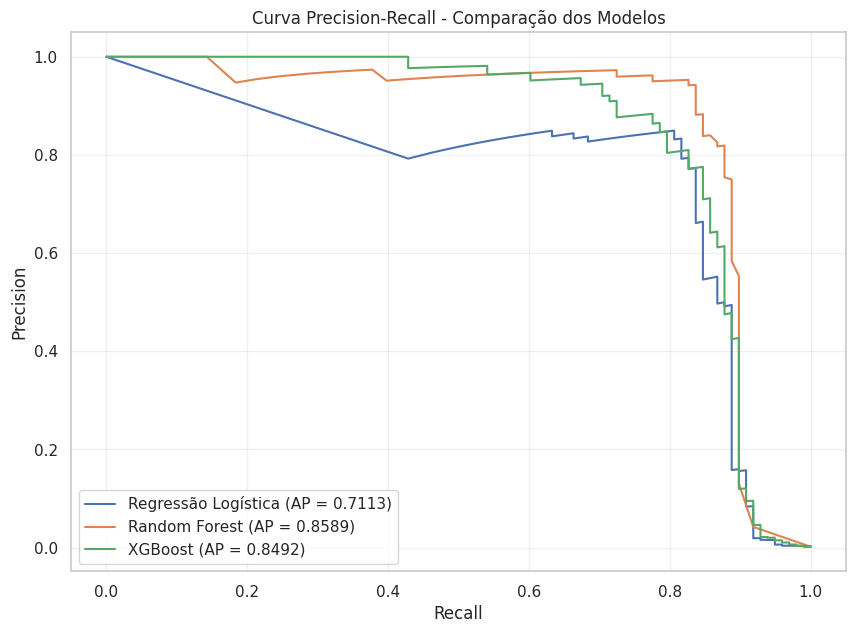

In [33]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(10, 7))

for nome, probabilidades in modelos_probabilidades.items():
    precision, recall, _ = precision_recall_curve(
        y_test,
        probabilidades
    )

    valor_ap = average_precision_score(
        y_test,
        probabilidades
    )

    plt.plot(
        recall,
        precision,
        label=f'{nome} (AP = {valor_ap:.4f})'
    )

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Curva Precision-Recall - Comparação dos Modelos')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 10.1. Interpretação das Curvas ROC e Precision-Recall

A curva ROC permite avaliar a capacidade dos modelos de distinguir transações fraudulentas das legítimas, considerando diferentes limiares de classificação.

Os resultados de ROC-AUC foram:

- **Regressão Logística:** 0,9711
- **Random Forest:** 0,9572
- **XGBoost:** 0,9810

Os três modelos apresentaram elevada capacidade de discriminação. O XGBoost obteve o maior ROC-AUC, indicando melhor separação geral entre as classes nessa métrica.

A curva Precision-Recall é especialmente relevante neste projeto, pois o conjunto de dados apresenta forte desequilíbrio entre transações legítimas e fraudulentas.

Os resultados de Average Precision (AP) foram:

- **Regressão Logística:** 0,7113
- **Random Forest:** 0,8589
- **XGBoost:** 0,8492

O Random Forest apresentou o maior Average Precision, demonstrando melhor equilíbrio geral entre precisão e recall ao longo dos diferentes limiares avaliados.

**Conclusão:** as curvas demonstram que a avaliação de um sistema de detecção de fraudes não deve depender exclusivamente da acurácia. É

## 11. Comparação Final dos Modelos

Nesta etapa, serão reunidas as principais métricas dos modelos desenvolvidos, permitindo comparar seu desempenho na identificação de transações fraudulentas.

Serão considerados Precision, Recall, F1-Score, ROC-AUC e PR-AUC, além da quantidade de falsos positivos e falsos negativos.

In [34]:
from sklearn.metrics import precision_score, recall_score, f1_score

resultados = pd.DataFrame({
    'Modelo': [
        'Regressão Logística',
        'Random Forest',
        'Random Forest Otimizado',
        'XGBoost'
    ],
    'Precision': [
        precision_score(y_test, y_pred_log),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf_otimizado),
        precision_score(y_test, y_pred_xgb)
    ],
    'Recall': [
        recall_score(y_test, y_pred_log),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_rf_otimizado),
        recall_score(y_test, y_pred_xgb)
    ],
    'F1-Score': [
        f1_score(y_test, y_pred_log),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_rf_otimizado),
        f1_score(y_test, y_pred_xgb)
    ],
    'ROC-AUC': [
        0.9711,
        0.9572,
        0.9766,
        0.9810
    ],
    'PR-AUC': [
        0.7113,
        0.8589,
        0.8177,
        0.8492
    ]
})

display(resultados.round(4))

,Modelo,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Regressão Logística,0.0603,0.9184,0.1131,0.9711,0.7113
1,Random Forest,0.9610,0.7551,0.8457,0.9572,0.8589
2,Random Forest Otimizado,0.8182,0.8265,0.8223,0.9766,0.8177
3,XGBoost,0.5548,0.8776,0.6798,0.9810,0.8492


### 11.1. Análise Comparativa dos Resultados

A comparação dos quatro modelos demonstrou diferenças importantes no desempenho da detecção de transações fraudulentas.

O Random Forest original obteve a maior Precision (0,9610), o maior F1-Score (0,8457) e o maior PR-AUC (0,8589), destacando-se pelo equilíbrio entre a identificação de fraudes e a redução de falsos positivos, considerando o limiar padrão de classificação.

A Regressão Logística apresentou o maior Recall (0,9184), identificando a maior proporção de transações fraudulentas. Entretanto, sua Precision foi de apenas 0,0603, indicando uma quantidade elevada de falsos positivos.

O XGBoost alcançou o maior ROC-AUC (0,9810), demonstrando excelente capacidade de distinguir transações legítimas e fraudulentas em diferentes limiares de classificação.

Já o Random Forest Otimizado apresentou ROC-AUC de 0,9766, mas não superou o modelo original nas métricas F1-Score e PR-AUC.

**Conclusão:** considerando os resultados obtidos com os limiares padrão, o Random Forest original apresentou o melhor desempenho geral em Precision, F1-Score e PR-AUC. Entretanto, a escolha definitiva deve considerar o custo dos falsos positivos e dos falsos negativos, especialmente em um sistema de detecção de fraudes.

In [35]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

limiares = [0.10, 0.15, 0.20, 0.25, 0.30,
            0.35, 0.40, 0.45, 0.50, 0.55,
            0.60, 0.65, 0.70, 0.75, 0.80]

resultados_limiares = []

for limiar in limiares:
    previsoes = (y_prob_rf >= limiar).astype(int)

    resultados_limiares.append({
        'Limiar': limiar,
        'Precision': precision_score(y_test, previsoes, zero_division=0),
        'Recall': recall_score(y_test, previsoes, zero_division=0),
        'F1-Score': f1_score(y_test, previsoes, zero_division=0)
    })

tabela_limiares = pd.DataFrame(resultados_limiares)

display(
    tabela_limiares
    .sort_values(by='F1-Score', ascending=False)
    .round(4)
    .reset_index(drop=True)
)

,Limiar,Precision,Recall,F1-Score
0,0.30,0.9318,0.8367,0.8817
1,0.35,0.9524,0.8163,0.8791
2,0.40,0.9512,0.7959,0.8667
3,0.25,0.8830,0.8469,0.8646
4,0.20,0.8646,0.8469,0.8557
5,0.45,0.9615,0.7653,0.8523
6,0.15,0.8190,0.8776,0.8473
7,0.50,0.9610,0.7551,0.8457
8,0.55,0.9600,0.7347,0.8324
9,0.60,0.9726,0.7245,0.8304


### 12.2. Análise dos Diferentes Limiares de Classificação

Foram testados 15 limiares de classificação para o modelo Random Forest original, com valores entre 0,10 e 0,80.

O melhor resultado observado foi obtido com o limiar de 0,30, que apresentou Precision de 0,9318, Recall de 0,8367 e F1-Score de 0,8817.

Em comparação com o limiar padrão de 0,50, o valor de 0,30 proporcionou aumento no Recall e no F1-Score, mantendo uma Precision elevada.

Os resultados demonstram que a escolha do limiar influencia diretamente o desempenho do sistema de detecção de fraudes, sendo necessário considerar o equilíbrio entre a identificação de fraudes e a redução de falsos alertas.

**Observação metodológica:** os resultados apresentados nesta análise foram calculados sobre o conjunto de teste e possuem caráter exploratório. Para evitar viés na avaliação final, o limiar deverá ser selecionado utilizando um conjunto de validação separado, antes da avaliação definitiva no conjunto de teste.

In [36]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score

# Separação dos dados de treinamento em treino e validação
X_treino_val, X_validacao, y_treino_val, y_validacao = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Treinamento de um novo Random Forest
modelo_rf_validacao = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

modelo_rf_validacao.fit(X_treino_val, y_treino_val)

# Probabilidades previstas para a validação
prob_validacao = modelo_rf_validacao.predict_proba(X_validacao)[:, 1]

# Avaliação de diferentes limiares na validação
resultados_validacao = []

for limiar in limiares:
    previsoes = (prob_validacao >= limiar).astype(int)

    resultados_validacao.append({
        'Limiar': limiar,
        'Precision': precision_score(y_validacao, previsoes, zero_division=0),
        'Recall': recall_score(y_validacao, previsoes, zero_division=0),
        'F1-Score': f1_score(y_validacao, previsoes, zero_division=0)
    })

tabela_validacao = pd.DataFrame(resultados_validacao)

display(
    tabela_validacao
    .sort_values(by='F1-Score', ascending=False)
    .round(4)
    .reset_index(drop=True)
)

,Limiar,Precision,Recall,F1-Score
0,0.30,0.8971,0.7722,0.8299
1,0.25,0.8841,0.7722,0.8243
2,0.35,0.8955,0.7595,0.8219
3,0.15,0.8611,0.7848,0.8212
4,0.20,0.8611,0.7848,0.8212
5,0.40,0.9077,0.7468,0.8194
6,0.50,0.9344,0.7215,0.8143
7,0.45,0.9194,0.7215,0.8085
8,0.10,0.8182,0.7975,0.8077
9,0.55,0.9474,0.6835,0.7941


In [37]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Treinamento final com todo o conjunto de treinamento
modelo_final = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

modelo_final.fit(X_train, y_train)

# Probabilidades no conjunto de teste
probabilidades_finais = modelo_final.predict_proba(X_test)[:, 1]

# Aplicação do limiar escolhido na validação
limiar_final = 0.30
previsoes_finais = (probabilidades_finais >= limiar_final).astype(int)

# Métricas finais
print("RESULTADOS FINAIS - RANDOM FOREST")
print(f"Limiar escolhido: {limiar_final:.2f}")
print(f"Precision: {precision_score(y_test, previsoes_finais):.4f}")
print(f"Recall:    {recall_score(y_test, previsoes_finais):.4f}")
print(f"F1-Score:  {f1_score(y_test, previsoes_finais):.4f}")

# Matriz de confusão
matriz = confusion_matrix(y_test, previsoes_finais)

print("\nMatriz de Confusão:")
print(matriz)

print("\nRelatório de Classificação:")
print(classification_report(
    y_test,
    previsoes_finais,
    target_names=['Transação legítima', 'Fraude']
))

RESULTADOS FINAIS - RANDOM FOREST
Limiar escolhido: 0.30
Precision: 0.9318
Recall:    0.8367
F1-Score:  0.8817

Matriz de Confusão:
[[56858     6]
 [   16    82]]

Relatório de Classificação:
                    precision    recall  f1-score   support

Transação legítima       1.00      1.00      1.00     56864
            Fraude       0.93      0.84      0.88        98

          accuracy                           1.00     56962
         macro avg       0.97      0.92      0.94     56962
      weighted avg       1.00      1.00      1.00     56962



### 13.2. Interpretação da Avaliação Final

O modelo Random Forest foi treinado utilizando todo o conjunto de treinamento e avaliado com o limiar de classificação de 0,30, selecionado previamente na etapa de validação.

Os resultados obtidos foram:

- Precision: 0,9318.
- Recall: 0,8367.
- F1-Score: 0,8817.

A matriz de confusão demonstrou que o modelo identificou corretamente 82 das 98 transações fraudulentas, deixando de detectar 16. Além disso, classificou incorretamente apenas 6 transações legítimas como fraudulentas.

Os resultados demonstram que o modelo conseguiu manter uma elevada precisão, identificando a maior parte das fraudes e produzindo uma quantidade relativamente pequena de falsos positivos.

**Ressalva metodológica:** o conjunto de teste já havia sido utilizado nas comparações anteriores e na exploração inicial dos limiares. Portanto, embora o limiar de 0,30 tenha sido selecionado com auxílio de um conjunto de validação separado, esta avaliação final não deve ser considerada uma estimativa completamente independente do desempenho. Uma avaliação independente exigiria um novo conjunto de dados ainda não utilizado nas análises.

## 14. Conclusão

O presente projeto teve como objetivo desenvolver e avaliar modelos de Machine Learning capazes de identificar transações fraudulentas em operações com cartões de crédito.

Durante a análise exploratória, foi identificado um forte desequilíbrio entre as classes: aproximadamente 99,83% das transações eram legítimas, enquanto apenas 0,17% correspondiam a fraudes. Essa característica tornou necessário utilizar métricas de avaliação mais adequadas, como Precision, Recall, F1-Score, ROC-AUC e PR-AUC, em vez de depender exclusivamente da acurácia.

Foram desenvolvidos e comparados quatro modelos: Regressão Logística, Random Forest, Random Forest Otimizado e XGBoost.

A análise demonstrou que cada algoritmo apresentou características distintas. A Regressão Logística obteve o maior Recall entre os modelos avaliados com o limiar padrão, enquanto o XGBoost alcançou o maior ROC-AUC. O Random Forest original, por sua vez, apresentou os melhores resultados de Precision, F1-Score e PR-AUC nessa comparação.

Também foram realizadas análises de importância das variáveis e interpretabilidade com SHAP, permitindo identificar quais atributos mais contribuíram para as previsões do modelo. Essas análises ajudaram a compreender o comportamento dos algoritmos, sem atribuir significado causal às variáveis.

Posteriormente, foram avaliados diferentes limiares de classificação. O valor de 0,30 apresentou o maior F1-Score entre os limiares testados no conjunto de validação, sendo selecionado para a